In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from quantmgmt.data.prices import download_prices
from quantmgmt.risk.returns import to_returns

SECTORES = ["XLK","XLF","XLE","XLV","XLI","XLY","XLP","XLU","XLB","XLRE"]
TICKERS = SECTORES + ["SPY"]
INICIO, FIN = "2009-12-01", "2026-10-01"   # FIN excluido: último mes completo = sep-2026

precios_mes = download_prices(TICKERS, start=INICIO, end=FIN).resample("ME").last()
rent = to_returns(precios_mes)
rent_10 = rent.loc["2015-11-30":, SECTORES]
rent_9 = rent[SECTORES].drop(columns="XLRE")
print(rent.index[-1].date(), rent_10.shape, rent_9.shape, rent_10.isna().sum().sum())

2026-09-30 (131, 10) (201, 9) 0


In [3]:
from quantmgmt.data.factors import download_ff_factors
factores = download_ff_factors(end="2026-09-30")
factores.tail()

TypeError: download_ff_factors() got an unexpected keyword argument 'end'

In [16]:
from quantmgmt.optimizers.mean_variance import (
    estimate_inputs, portfolio_stats, min_variance, max_sharpe, efficient_frontier, target_volatility,
)
mu, sigma = estimate_inputs(rent_10)
rf = factores["RF"].reindex(rent_10.index).mean() * 12   # RF medio anual del periodo
w_mv = min_variance(sigma)
w_mv.round(3).sort_values(ascending=False)

XLP     0.377
XLV     0.301
XLU     0.229
XLK     0.087
XLF     0.006
XLE     0.000
XLI     0.000
XLY     0.000
XLB     0.000
XLRE    0.000
Name: min_variance, dtype: float64

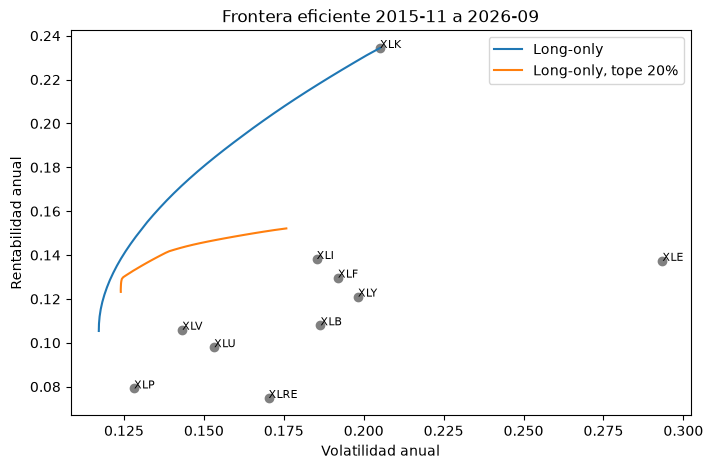

count    40.0000
mean      4.0000
std       0.9337
min       1.0000
25%       3.7500
50%       4.0000
75%       5.0000
max       5.0000
dtype: float64
count    40.000000
mean      6.550000
std       0.552384
min       5.000000
25%       6.000000
50%       7.000000
75%       7.000000
max       7.000000
dtype: float64


In [17]:
import matplotlib.pyplot as plt
from quantmgmt.optimizers.mean_variance import efficient_frontier

fr_libre = efficient_frontier(mu, sigma, n_points=40)
fr_20 = efficient_frontier(mu, sigma, n_points=40, max_weight=0.20)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fr_libre.vol, fr_libre.ret, label="Long-only")
ax.plot(fr_20.vol, fr_20.ret, label="Long-only, tope 20%")
ax.scatter(np.sqrt(np.diag(sigma)), mu, c="grey")
for t in mu.index:
    ax.annotate(t, (np.sqrt(sigma.loc[t, t]), mu[t]), fontsize=8)
ax.set(xlabel="Volatilidad anual", ylabel="Rentabilidad anual", title="Frontera eficiente 2015-11 a 2026-09")
ax.legend(); plt.show()

# concentración: cuántos activos tienen un peso de más del 1% en cada punto
SECT = list(mu.index)
print((fr_libre[SECT] > 0.01).sum(axis=1).describe())
print((fr_20[SECT] > 0.01).sum(axis=1).describe())